In [6]:
#Install the required libraries
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [8]:
#Loading dataset
df = pd.read_excel("Online Retail.xlsx")

In [9]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [10]:
#Checking column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [11]:
#checking the missing values
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [12]:
#View basic statistics
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


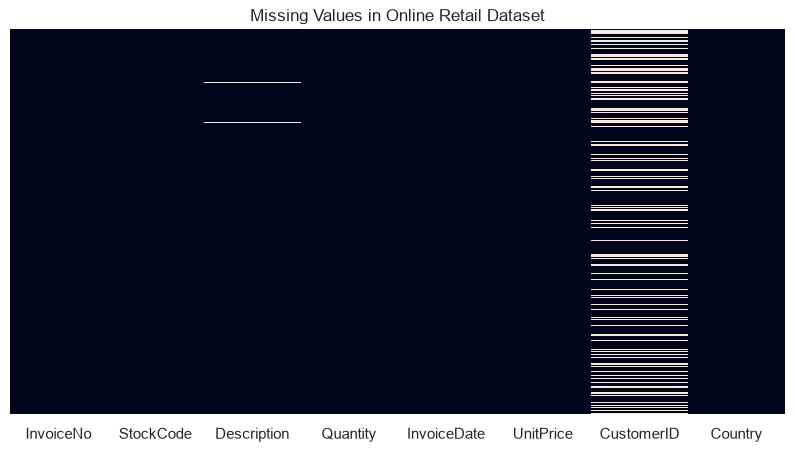

In [16]:
#Visualize missing customer IDs
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in Online Retail Dataset")
plt.show()

In [17]:
#cleaning
df_clean = df.dropna(subset=["CustomerID"]).copy()

df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)

df_clean = df_clean[
    (~df_clean["InvoiceNo"].str.startswith("C")) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

df_clean["Revenue"] = (df_clean["Quantity"] * df_clean["UnitPrice"])

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Unique customers:", df_clean["CustomerID"].nunique())

df_clean.head()

Original records: 541909
Cleaned records: 397884
Unique customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


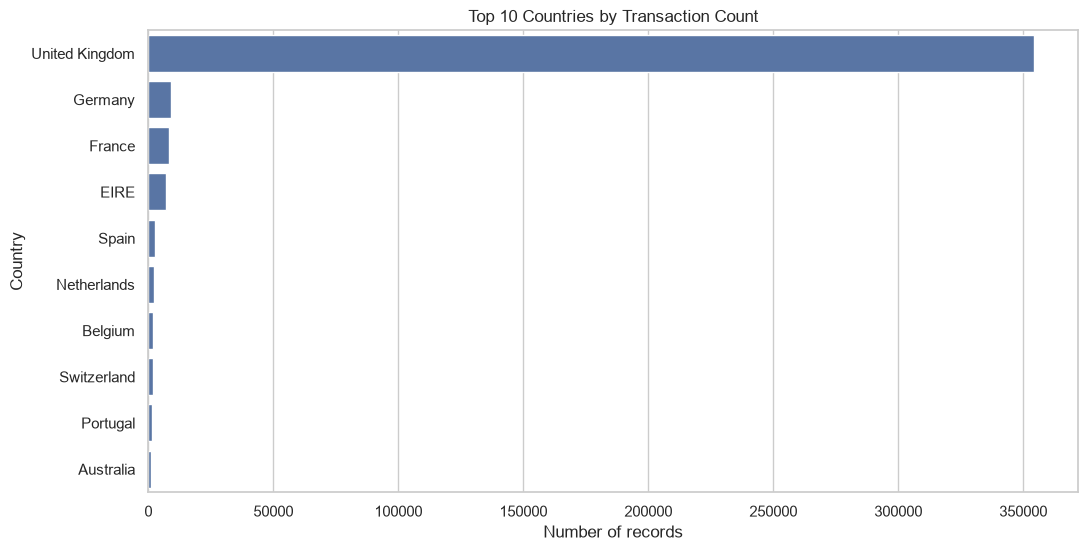

In [18]:
#Perform exploratory data analysis
country_counts = df_clean["Country"].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=country_counts.values, y=country_counts.index)

plt.title("Top 10 Countries by Transaction Count")
plt.xlabel("Number of records")
plt.ylabel("Country")
plt.show()

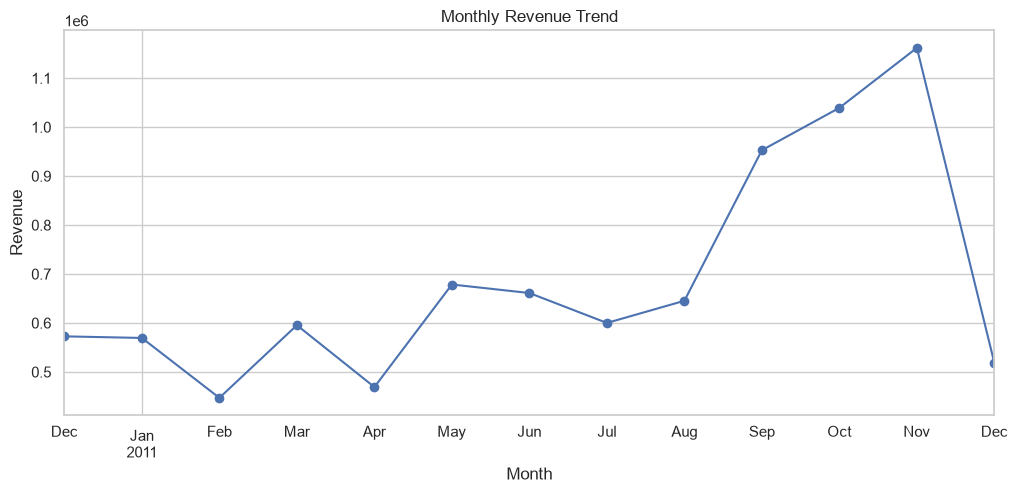

In [19]:
#Monthly revenue trend
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"]
)

monthly_revenue = (
    df_clean.set_index("InvoiceDate")["Revenue"]
    .resample("ME")
    .sum()
)

plt.figure(figsize=(12, 5))
monthly_revenue.plot(marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

In [25]:
#RFM features
snapshot_date = (
    df_clean["InvoiceDate"].max() + pd.Timedelta(days=1))

rfm = df_clean.groupby("CustomerID").agg(Recency=("InvoiceDate",lambda x: (snapshot_date - x.max()).days),Frequency=("InvoiceNo", "nunique"),Monetary=("Revenue", "sum"))

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [21]:
#Inspect the resulting dataset
print("Number of customers:", len(rfm))
rfm.describe()

Number of customers: 4338


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


In [24]:
#Scale the features
X = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (4338, 3)


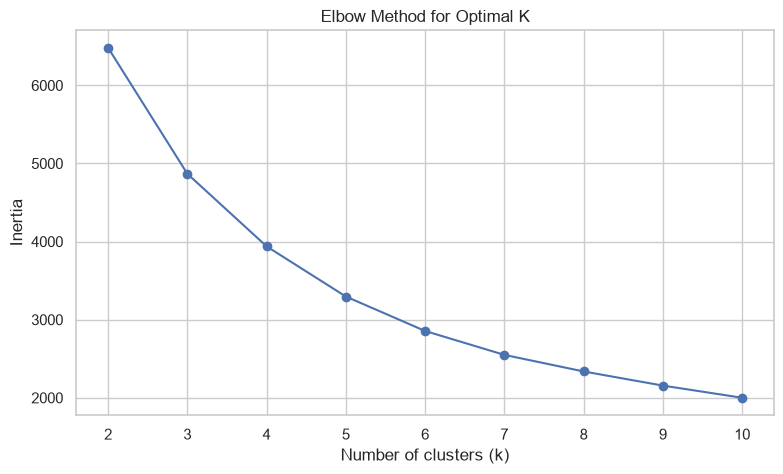

In [27]:
#Find the optimal number of clusters
inertia = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(range(2, 11), inertia, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.show()

In [28]:
#calculating silhouette scores
for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(5000, len(X_scaled)),
        random_state=42
    )

    print(f"k = {k}, Silhouette Score = {score:.3f}")

k = 2, Silhouette Score = 0.433
k = 3, Silhouette Score = 0.337
k = 4, Silhouette Score = 0.337
k = 5, Silhouette Score = 0.316
k = 6, Silhouette Score = 0.313
k = 7, Silhouette Score = 0.310


In [29]:
#Training the final model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,2
12347,2,7,4310.00,1
12348,75,4,1797.24,2
12349,19,1,1757.55,0
12350,310,1,334.40,3


#### Analyze your customer segment

In [30]:

cluster_summary = rfm.groupby("Cluster").agg(Customer_Count=("Recency", "size"),Avg_Recency=("Recency", "mean"),Avg_Frequency=("Frequency", "mean"),Avg_Monetary=("Monetary", "mean")).round(2)

cluster_summary

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,837,18.12,2.15,551.82
1,716,12.13,13.71,8074.27
2,1173,71.08,4.08,1802.83
3,1612,182.50,1.32,343.45


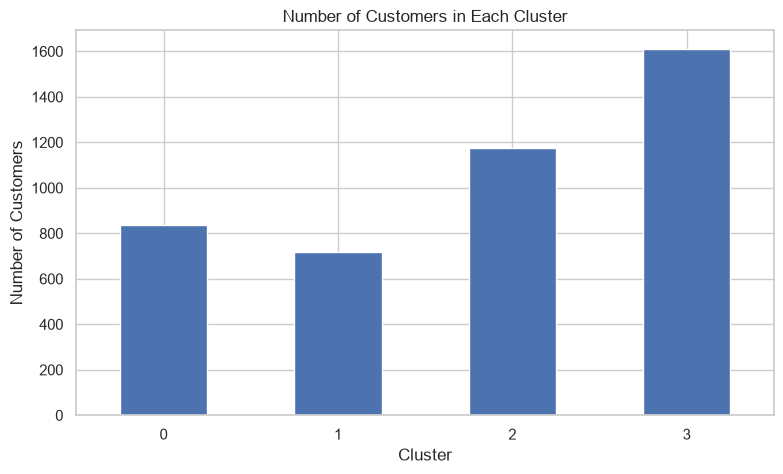

In [31]:
#Visualising the results
cluster_summary["Customer_Count"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

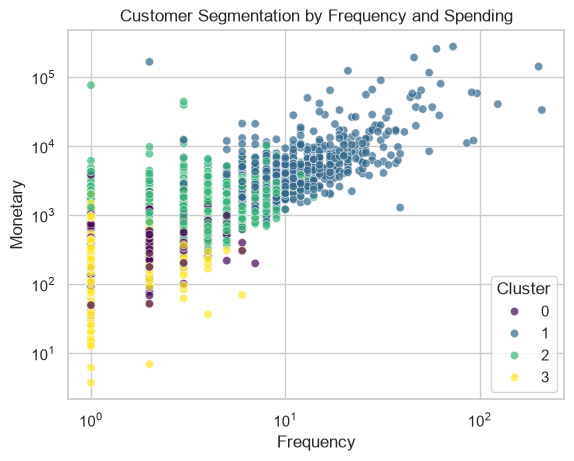

In [32]:
sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.7
)

plt.xscale("log")
plt.yscale("log")
plt.title("Customer Segmentation by Frequency and Spending")
plt.show()

In [33]:
#saving the final dataset
rfm.to_csv("customer_segments.csv", index=True)


#### Comparing multiple clustering models

In [39]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    results.append({"k": k,"inertia": model.inertia_,"silhouette_score": silhouette_score(X_scaled,labels,sample_size=min(5000, len(X_scaled)),random_state=42)})

evaluation = pd.DataFrame(results)
evaluation

,k,inertia,silhouette_score
0,2,6481.225323,0.432940
1,3,4867.846645,0.336510
2,4,3938.509954,0.337134
3,5,3295.976329,0.316097
4,6,2855.011247,0.313329
5,7,2548.914324,0.309975
6,8,2336.777508,0.300782


#### Visualizing the comparison

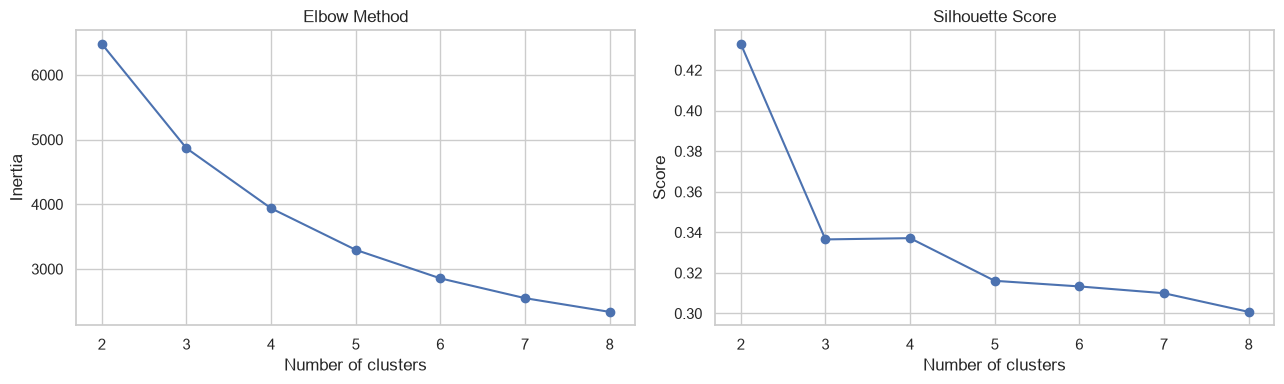

In [36]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    evaluation["k"], evaluation["inertia"], marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    evaluation["k"], evaluation["silhouette_score"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

#### Creating interpretable customer personas

In [37]:

# Set this to your chosen number of clusters
best_k = 4

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = final_model.fit_predict(X_scaled)

profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Spending=("Monetary", "median"),
    Total_Revenue=("Monetary", "sum")
).round(2)

profile["Customer_Percentage"] = (
    profile["Customers"] / len(rfm) * 100
).round(2)

profile.sort_values("Median_Spending", ascending=False)

,Customers,Median_Recency,Median_Frequency,Median_Spending,Total_Revenue,Customer_Percentage
Cluster,,,,,,
1,716,8.0,10.0,3733.87,5781175.08,16.51
2,1173,56.0,4.0,1345.62,2114718.42,27.04
0,837,17.0,2.0,471.70,461872.95,19.29
3,1612,177.0,1.0,298.26,553641.45,37.16


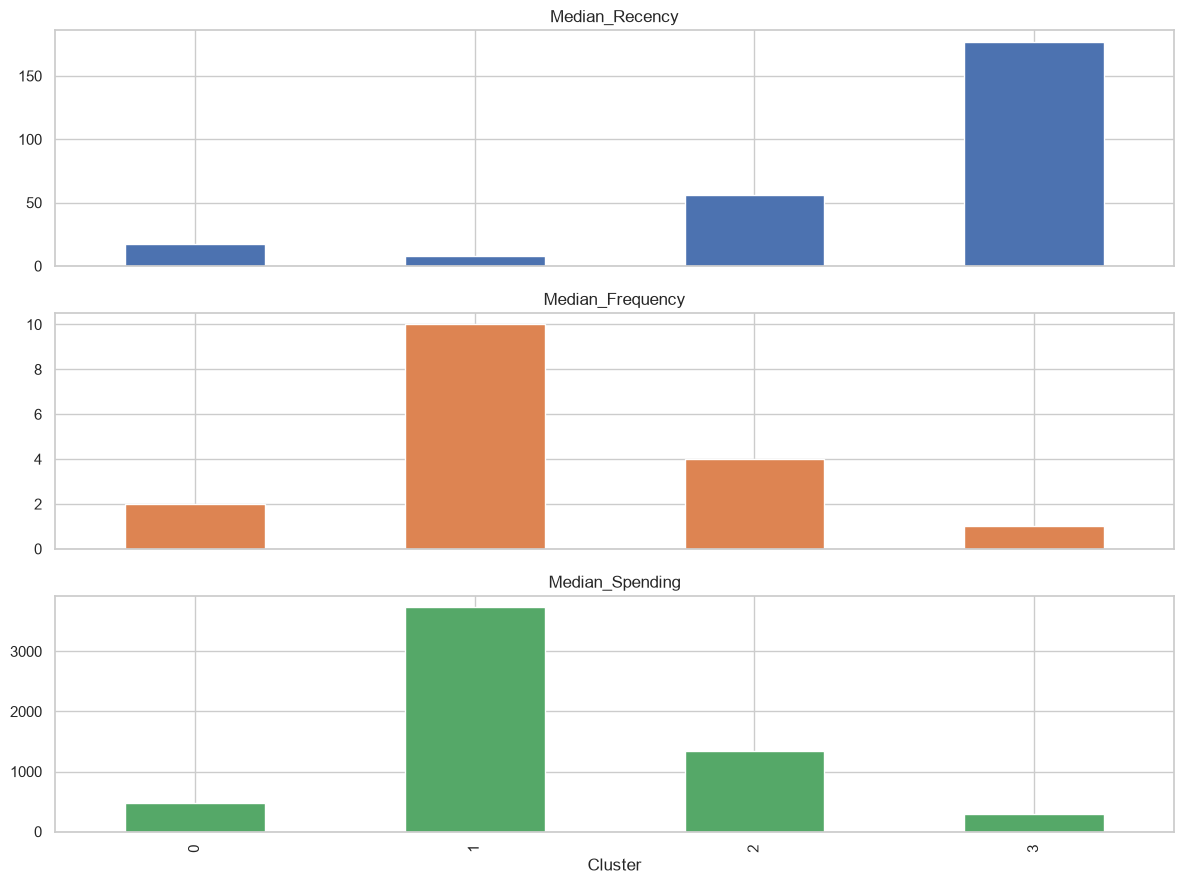

In [38]:
#Creating a visual profile
profile[["Median_Recency","Median_Frequency","Median_Spending"]].plot(kind="bar", subplots=True, figsize=(12, 9),legend=False)

plt.tight_layout()
plt.show()

#### Building a customer inactivity risk indicator

In [40]:
# Illustrative business threshold; validate for your use case
inactivity_threshold = 90

rfm["Inactivity_Risk"] = np.where(rfm["Recency"] >= inactivity_threshold,"Needs Attention", "Recently Active")

rfm["Inactivity_Risk"].value_counts()

Inactivity_Risk
Recently Active    2880
Needs Attention    1458
Name: count, dtype: int64

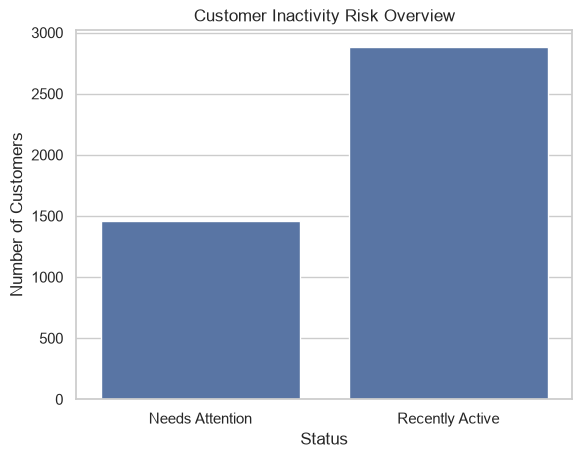

In [41]:
sns.countplot(data=rfm,x="Inactivity_Risk")

plt.title("Customer Inactivity Risk Overview")
plt.xlabel("Status")
plt.ylabel("Number of Customers")
plt.show()

#### Generating marketing recommendations

In [42]:
def recommend_action(row):
    if (
        row["Median_Spending"] >=
        profile["Median_Spending"].median()
        and row["Median_Frequency"] >=
        profile["Median_Frequency"].median()
    ):
        return "Loyalty rewards and VIP offers"

    elif row["Median_Recency"] >= inactivity_threshold:
        return "Re-engagement campaign"

    elif row["Median_Frequency"] <= 2:
        return "Encourage a second purchase"

    else:
        return "Personalized product recommendations"


profile["Marketing_Action"] = profile.apply(
    recommend_action, axis=1
)

profile[[
    "Customers",
    "Median_Recency",
    "Median_Frequency",
    "Median_Spending",
    "Marketing_Action"
]]

,Customers,Median_Recency,Median_Frequency,Median_Spending,Marketing_Action
Cluster,,,,,
0,837,17.0,2.0,471.70,Encourage a second purchase
1,716,8.0,10.0,3733.87,Loyalty rewards and VIP offers
2,1173,56.0,4.0,1345.62,Loyalty rewards and VIP offers
3,1612,177.0,1.0,298.26,Re-engagement campaign


#### Discover best-selling products and revenue drivers

In [45]:
product_summary = (df_clean.groupby("Description").agg(Units_Sold=("Quantity", "sum"),Revenue=("Revenue", "sum"),Orders=("InvoiceNo", "nunique")).sort_values("Revenue", ascending=False))

product_summary.head(10)

,Units_Sold,Revenue,Orders
Description,,,
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
REGENCY CAKESTAND 3 TIER,12402,142592.95,1703
WHITE HANGING HEART T-LIGHT HOLDER,36725,100448.15,1971
JUMBO BAG RED RETROSPOT,46181,85220.78,1600
MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73,195
POSTAGE,3120,77803.96,1099
PARTY BUNTING,15291,68844.33,1379
ASSORTED COLOUR BIRD ORNAMENT,35362,56580.34,1375
Manual,7173,53779.93,253


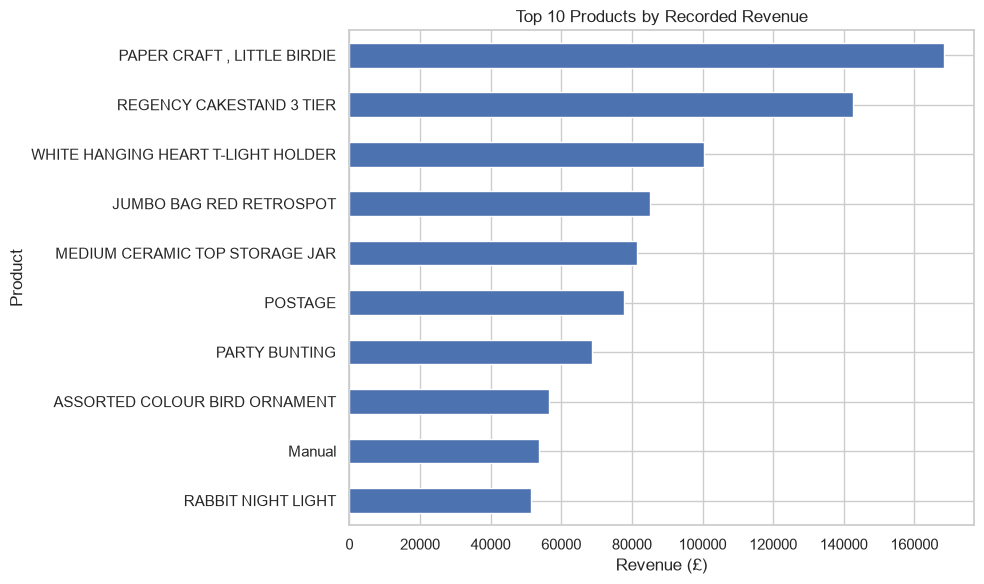

In [46]:
top_products = product_summary.head(10).sort_values("Revenue")

top_products["Revenue"].plot(
    kind="barh", figsize=(10, 6)
)

plt.title("Top 10 Products by Recorded Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

#### Adding an executive summary and export your results

In [49]:
total_customers = len(rfm)
total_revenue = df_clean["Revenue"].sum()
average_spend = rfm["Monetary"].mean()
risk_count = (rfm["Inactivity_Risk"] == "Needs Attention").sum()

print("CUSTOMER INTELLIGENCE REPORT :")

print(f"Customers analyzed: {total_customers:,}")
print(f"Recorded revenue: £{total_revenue:,.2f}")
print(f"Average customer spend: £{average_spend:,.2f}")
print(f"Customers needing attention: {risk_count:,}")
print(f"Customer clusters: {rfm['Cluster'].nunique()}")

CUSTOMER INTELLIGENCE REPORT :
Customers analyzed: 4,338
Recorded revenue: £8,911,407.90
Average customer spend: £2,054.27
Customers needing attention: 1,458
Customer clusters: 4


In [50]:
rfm.to_csv("customer_segments.csv", index=True)
profile.to_csv("customer_segment_profiles.csv", index=True)
product_summary.to_csv("product_performance.csv", index=True)
evaluation.to_csv("model_evaluation.csv", index=False)

print("All reports exported successfully.")

All reports exported successfully.
